# A network of 100 000 people: 80 gigabytes or 8 megabytes

A graph is a set of vertices and a set of edges, and the lecture gave two ways
to store one, the adjacency matrix and the adjacency list, and one algorithm
to explore one, breadth-first search. This notebook shows why the choice of
representation decides whether a social network fits in memory at all, and why
the queue inside BFS is what makes its paths shortest.

## 1. Matrix or list?

A social network of $n$ people with about $k$ friends each has $nk/2$ edges.
The adjacency matrix has $n^2$ entries whether they are 0 or 1; the adjacency
list stores only the edges. We build both for a small random network and
measure them, then scale the numbers up.

In [1]:
import random
import numpy as np

def random_network(n, k, seed=5):
    # undirected graph with n vertices and about k neighbors each, as adjacency lists
    rnd = random.Random(seed)
    neighbors = [[] for _ in range(n)]
    for _ in range(n * k // 2):
        u, v = rnd.randrange(n), rnd.randrange(n)
        if u != v and v not in neighbors[u]:
            neighbors[u].append(v); neighbors[v].append(u)
    return neighbors

n, k = 5_000, 10
adj_list = random_network(n, k)
adj_matrix = np.zeros((n, n), dtype=np.int8)               # one byte per entry
for u, nbrs in enumerate(adj_list):
    adj_matrix[u, nbrs] = 1

edges = sum(len(x) for x in adj_list) // 2
print(f"{n} people, {edges} friendships")
print(f"matrix: {adj_matrix.nbytes / 1e6:8.1f} MB   ({n} x {n} entries, almost all 0)")
print(f"lists:  {edges * 2 * 8 / 1e6:8.1f} MB   ({edges * 2} neighbor entries at 8 bytes)")

5000 people, 24974 friendships
matrix:     25.0 MB   (5000 x 5000 entries, almost all 0)
lists:       0.4 MB   (49948 neighbor entries at 8 bytes)


For 5 000 people the matrix is 25 MB and the lists are under a megabyte.
Now scale: the matrix grows with $n^2$, the lists with $nk$.

In [2]:
for people in [5_000, 100_000, 2_000_000]:
    matrix_gb = people ** 2 / 1e9
    lists_gb = people * k * 8 / 1e9
    print(f"{people:>10} people   matrix {matrix_gb:10.1f} GB   lists {lists_gb:8.3f} GB")

      5000 people   matrix        0.0 GB   lists    0.000 GB
    100000 people   matrix       10.0 GB   lists    0.008 GB
   2000000 people   matrix     4000.0 GB   lists    0.160 GB


At 100 000 people, a mid-sized online community, the matrix needs 10 GB at
one byte per entry, and 80 GB with the 8-byte numbers that `np.zeros` uses by
default, more than any laptop has, while the lists need 8 MB. At two million people the matrix would take 4 terabytes. Real
social networks are sparse, each person knows a few hundred of the millions,
and the representation has to exploit that or the analysis does not start.

The matrix is not useless: asking "are $u$ and $v$ friends?" is one lookup in
the matrix and a scan of a short list in the other. Listing the friends of
$u$ is the opposite: a row of $n$ entries in the matrix, a list of $k$ in the
other. Which one you need depends on the questions you ask most.

In [3]:
import time

u = 17
t0 = time.perf_counter()
for _ in range(1000):
    friends_m = np.flatnonzero(adj_matrix[u])        # scan a row of n entries
t_matrix = time.perf_counter() - t0
t0 = time.perf_counter()
for _ in range(1000):
    friends_l = adj_list[u]                          # already a list of k
t_list = time.perf_counter() - t0
print(f"friends of {u}: {sorted(friends_l)}")
print(f"1000 times 'list the friends': matrix {t_matrix * 1000:.1f} ms, lists {t_list * 1000:.3f} ms")

friends of 17: [818, 1417, 1716, 3162, 4746]
1000 times 'list the friends': matrix 28.2 ms, lists 0.238 ms


## 2. Breadth-first search and the six degrees

BFS finds the distance from one person to everyone else, in hops, and the
lecture's version keeps the frontier in a queue: first in, first out. Here it
is with a `deque`, run from one person in the 5 000-person network, and the
resulting distances plotted.

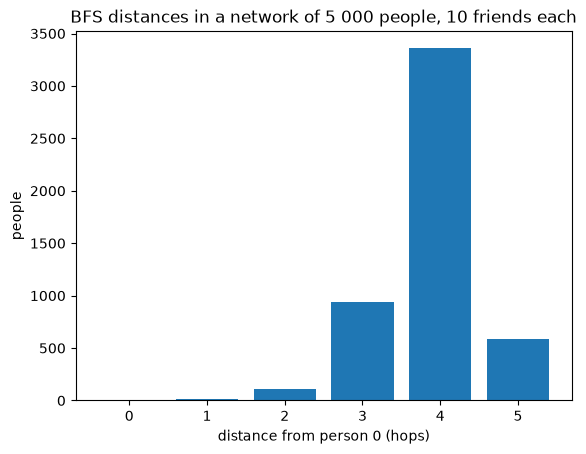

reached 5000 of 5000; mean distance 3.88, maximum 5


In [4]:
from collections import deque
import matplotlib.pyplot as plt

def bfs(neighbors, source):
    distance = [None] * len(neighbors)
    distance[source] = 0
    queue = deque([source])
    while queue:
        u = queue.popleft()                 # take the oldest vertex in the queue
        for v in neighbors[u]:
            if distance[v] is None:         # WHITE: not seen yet
                distance[v] = distance[u] + 1
                queue.append(v)
    return distance

dist = bfs(adj_list, 0)
reached = [d for d in dist if d is not None]
plt.hist(reached, bins=range(max(reached) + 2), align="left", rwidth=0.8)
plt.xlabel("distance from person 0 (hops)"); plt.ylabel("people")
plt.title("BFS distances in a network of 5 000 people, 10 friends each")
plt.show()
print(f"reached {len(reached)} of {n}; mean distance {np.mean(reached):.2f}, maximum {max(reached)}")

Almost everyone is within four or five hops of person 0, even though each
person knows only ten others: the number of people at distance $d$ grows
roughly like $10^d$ until it runs out of network. That is the small-world
effect, measured, and BFS is the algorithm behind every "degrees of
separation" number you have read.

## 3. Why a queue and not a stack

The only difference between BFS and depth-first search is the container:
BFS takes the oldest vertex, DFS the newest. Change `popleft()` to `pop()`
and the search still reaches everyone, but the distances it records are no
longer shortest.

In [5]:
def stack_search(neighbors, source):
    distance = [None] * len(neighbors)
    distance[source] = 0
    stack = [source]
    while stack:
        u = stack.pop()                     # take the newest vertex instead
        for v in neighbors[u]:
            if distance[v] is None:
                distance[v] = distance[u] + 1
                stack.append(v)
    return distance

dist_stack = stack_search(adj_list, 0)
longer = sum(1 for a, b in zip(dist, dist_stack) if a is not None and b > a)
print(f"reached with the stack: {sum(d is not None for d in dist_stack)} of {n}")
print(f"people whose recorded distance is longer than the true one: {longer}")
print(f"largest recorded distance: BFS {max(reached)}, stack {max(d for d in dist_stack if d is not None)}")

reached with the stack: 5000 of 5000
people whose recorded distance is longer than the true one: 4963
largest recorded distance: BFS 5, stack 922


With the stack the search dives deep before it looks around, so it reaches
most people by a long chain and records distances in the hundreds where the
truth is four or five. Same graph, same code but for one method
call, and the answer to "how far apart are two people?" is wrong for nearly
everyone. The correctness of BFS is not in the loop, it is in the queue.

**What we used:** [representing graphs](../Transcripts/05-Algorithms.md#8-representing-graphs),
[queues and stacks](../Transcripts/05-Algorithms.md#6-abstract-data-structures-queues-and-stacks),
[breadth-first search](../Transcripts/05-Algorithms.md#9-breadth-first-search) and
[graphs in social science](../Transcripts/05-Algorithms.md#10-graphs-in-social-science) from session 5.